# Online Shoppers: Data Cleaning and Preparation

Prepare the Online Shoppers dataset for the AAI-501 team project. Use `dataset/online_shoppers_intention.csv` when available; otherwise fetch dataset 468 directly from UCI using `ucimlrepo` (internet required). Set `USE_UCI = True` to fetch even when a local CSV exists. This notebook audits the actual CSV, removes exact duplicate records, separates a held-out test set, and fits preprocessing **only on training data**. It does not train or evaluate a classifier.

The project will compare full and reduced feature sets and examine visitor behavior. These are session summaries: the prepared data do not demonstrate early-session forecasting or causal effects of marketing interventions.

Run the cells in order. If dependencies are missing, run the optional installation cell and restart the kernel. The CSV remains unchanged.

In [1]:
# Optional: uncomment in a notebook kernel that needs dependencies.
%pip install pandas scikit-learn matplotlib joblib
%pip install ucimlrepo


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TEST_SIZE = 0.20
# Resolve a repository root even when the CSV has not been downloaded.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "README.md").is_file() and (p / "notebooks").is_dir()),
            Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
DATA_PATH = ROOT / "dataset" / "online_shoppers_intention.csv"
USE_UCI = False  # True forces a fresh UCI fetch; False prefers the local CSV.
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)


pandas: 3.1.1 | scikit-learn: 1.9.1


## 1. Load and validate the schema

Treat integer identifiers such as browser and region as nominal categories, rather than ordered measurements. Parse boolean values explicitly so that the string `FALSE` cannot accidentally become `True`. Invalid nonempty numeric or boolean tokens raise an error instead of silently disappearing into imputation.

In [3]:
if DATA_PATH.is_file() and not USE_UCI:
    raw = pd.read_csv(DATA_PATH)
    data_source = str(DATA_PATH.relative_to(ROOT))
    source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
    hash_basis = "Original local CSV bytes"
else:
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError as exc:
        raise ImportError("Install the UCI client with %pip install ucimlrepo, then rerun this cell.") from exc

    # Fetch dataset as pandas DataFrames. Network errors propagate so they
    # are not mistaken for missing data or silently replaced with other data.
    online_shoppers_purchasing_intention_dataset = fetch_ucirepo(id=468)
    X = online_shoppers_purchasing_intention_dataset.data.features
    y = online_shoppers_purchasing_intention_dataset.data.targets
    if X is None or y is None:
        raise ValueError("UCI did not return both features and targets.")
    if not X.index.equals(y.index):
        raise ValueError("UCI feature and target row indices do not match.")
    raw = pd.concat([X, y], axis=1)

    # Metadata and variable information supplied by UCI.
    print(online_shoppers_purchasing_intention_dataset.metadata)
    display(online_shoppers_purchasing_intention_dataset.variables)
    data_source = "UCI Machine Learning Repository, dataset 468 (ucimlrepo)"
    source_sha256 = hashlib.sha256(raw.to_csv(index=False).encode("utf-8")).hexdigest()
    hash_basis = "Fetched DataFrame serialized as UTF-8 CSV; not the original source file"
print("Data source:", data_source)
raw.columns = raw.columns.str.strip()
NUMERIC = ["Administrative", "Administrative_Duration", "Informational",
           "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
           "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
BOOLEAN = ["Weekend"]
TARGET = "Revenue"
FEATURES = NUMERIC + CATEGORICAL + BOOLEAN
expected = FEATURES + [TARGET]
missing_columns = set(expected) - set(raw.columns)
extra_columns = set(raw.columns) - set(expected)
if missing_columns or extra_columns or raw.columns.duplicated().any():
    raise ValueError(f"Unexpected schema: missing={missing_columns}, extra={extra_columns}")
print("Raw shape:", raw.shape)
display(raw.head())
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum()}))


Data source: dataset/online_shoppers_intention.csv
Raw shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,dtype,missing
Administrative,int64,0
Administrative_Duration,float64,0
Informational,int64,0
Informational_Duration,float64,0
ProductRelated,int64,0
ProductRelated_Duration,float64,0
BounceRates,float64,0
ExitRates,float64,0
PageValues,float64,0
SpecialDay,float64,0


In [4]:
clean = raw.copy()
for col in clean.select_dtypes(include=["object", "string"]).columns:
    clean[col] = clean[col].astype("string").str.strip().replace("", pd.NA)

for col in NUMERIC:
    clean[col] = pd.to_numeric(clean[col], errors="raise")
    if np.isinf(clean[col].dropna().to_numpy(dtype=float)).any():
        raise ValueError(f"Infinite values in {col}")
    if (clean[col].dropna() < 0).any():
        raise ValueError(f"Negative values in nonnegative feature {col}")
for col in ["BounceRates", "ExitRates", "SpecialDay"]:
    if not clean[col].dropna().between(0, 1).all():
        raise ValueError(f"Values outside [0, 1] in {col}")

boolean_map = {"true": 1, "false": 0, "1": 1, "0": 0}
for col in BOOLEAN + [TARGET]:
    tokens = clean[col].astype("string").str.lower()
    invalid = tokens.notna() & ~tokens.isin(boolean_map)
    if invalid.any():
        raise ValueError(f"Invalid booleans in {col}: {tokens[invalid].unique().tolist()}")
    clean[col] = tokens.map(boolean_map).astype(float)

# Retain missing predictors for training-only imputation. Never impute labels.
if clean[TARGET].isna().any():
    raise ValueError("Missing Revenue labels: investigate before proceeding.")
clean[TARGET] = clean[TARGET].astype(int)
for col in CATEGORICAL:
    # Normalize numeric category codes and use np.nan for sklearn imputers.
    if col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
        codes = pd.to_numeric(clean[col], errors="raise")
        if ((codes.dropna() % 1 != 0) | (codes.dropna() < 1)).any():
            raise ValueError(f"Invalid category codes in {col}")
        clean[col] = codes.astype("Int64").astype("string")
    clean[col] = clean[col].astype(object).where(clean[col].notna(), np.nan)

# Remove exact duplicate labeled records before splitting to prevent identical
# rows appearing in both training and test sets. Preserve source row indices.
duplicate_count = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()
# Identical predictors with conflicting labels are reported, not arbitrarily removed.
conflicting = clean.groupby(FEATURES, dropna=False)[TARGET].nunique()
print("Exact duplicate rows removed:", duplicate_count)
print("Predictor patterns with conflicting labels:", int((conflicting > 1).sum()))
print("Cleaned shape:", clean.shape)
display(clean.isna().sum().to_frame("remaining_missing"))


Exact duplicate rows removed: 125
Predictor patterns with conflicting labels: 0
Cleaned shape: (12205, 18)


,remaining_missing
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


## 2. Reserve the test set

Split before exploratory analysis or feature selection. Stratification preserves approximately the same purchase proportion in both partitions. Keep source row indices so the split can be reproduced. Exact duplicates have been removed, but without customer identifiers we cannot guarantee customer independence across partitions. This random split measures performance on held-out sessions, not future periods.

In [5]:
X = clean[FEATURES].copy()
y = clean[TARGET].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(clean)
assert set(y.unique()) == {0, 1}
print("Training rows:", len(X_train), "| Reserved test rows:", len(X_test))
display(y_train.value_counts().rename_axis("Revenue").to_frame("training_sessions"))
print(f"Training purchase rate: {y_train.mean():.2%}")


Training rows: 9764 | Reserved test rows: 2441


,training_sessions
Revenue,
0,8238
1,1526


Training purchase rate: 15.63%


## 3. Initial exploratory checks on training data

Use these summaries to guide deeper analysis. Correlation indicates association, not causation or proof of confounding. Examine relationships within visitor groups as well as overall. Do not delete long sessions merely because they are outliers: skewed durations may describe real behavior. Fit any later clipping or transformation inside training folds.

,count,mean,std,min,25%,50%,75%,max
Administrative,9764.0,2.342687,3.349268,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,9764.0,82.219938,179.502363,0.0,0.000000,9.000000,94.725000,3398.750000
Informational,9764.0,0.510344,1.282728,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,9764.0,34.950623,143.828323,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,9764.0,32.101803,44.817312,0.0,8.000000,18.000000,39.000000,705.000000
ProductRelated_Duration,9764.0,1207.264687,1926.389159,0.0,193.466667,617.000000,1483.650000,63973.522230
BounceRates,9764.0,0.020296,0.045234,0.0,0.000000,0.002857,0.016667,0.200000
ExitRates,9764.0,0.041469,0.046145,0.0,0.014286,0.025000,0.049242,0.200000
PageValues,9764.0,5.945606,18.860076,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,9764.0,0.062351,0.199959,0.0,0.000000,0.000000,0.000000,1.000000



Month:


,training_sessions
Month,
May,2674
Nov,2358
Mar,1500
Dec,1363
Oct,433
Aug,360
Sep,354
Jul,353
June,225



OperatingSystems:


,training_sessions
OperatingSystems,
2,5237
3,2048
1,2010
4,383
8,63
6,12
7,6
5,5



Browser:


... (4 outputs left out)

,training_sessions
TrafficType,
2,3111
1,1944
3,1611
4,858
13,564
6,367
10,351
8,267
5,197



VisitorType:


,training_sessions
VisitorType,
Returning_Visitor,8347
New_Visitor,1349
Other,68


,sessions,purchases,purchase_rate
VisitorType,,,
New_Visitor,1349,325,0.240919
Other,68,16,0.235294
Returning_Visitor,8347,1185,0.141967


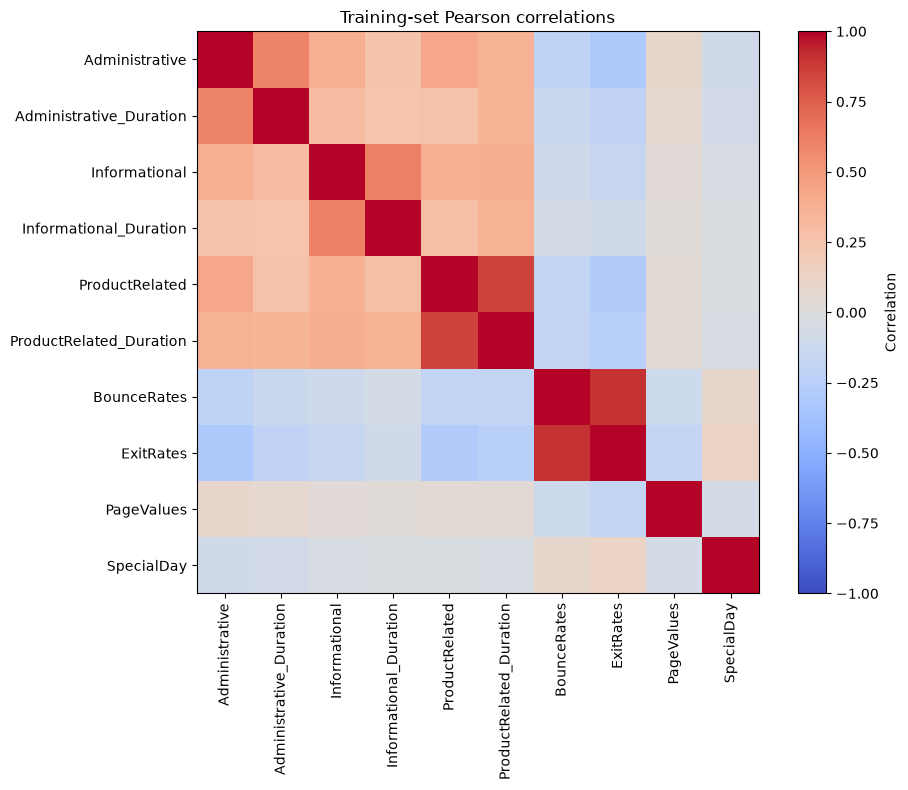

correlation
BounceRates            ExitRates                   0.899991
ProductRelated         ProductRelated_Duration     0.853018
Informational          Informational_Duration      0.616406
Administrative         Administrative_Duration     0.596141
                       ProductRelated              0.425666
Informational          ProductRelated_Duration     0.397457
                       ProductRelated              0.378564
Administrative         Informational               0.376155
                       ProductRelated_Duration     0.367287
Informational_Duration ProductRelated_Duration     0.361699

In [6]:
display(X_train[NUMERIC].describe().T)
for col in CATEGORICAL:
    print(f"\n{col}:")
    display(X_train[col].value_counts(dropna=False).to_frame("training_sessions"))
training_analysis = X_train.assign(Revenue=y_train)
display(training_analysis.groupby("VisitorType", dropna=False)["Revenue"]
        .agg(sessions="size", purchases="sum", purchase_rate="mean"))
corr = X_train[NUMERIC].corr()
fig, ax = plt.subplots(figsize=(10, 8))
heat = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=90)
ax.set_yticks(range(len(NUMERIC)), NUMERIC)
ax.set_title("Training-set Pearson correlations")
fig.colorbar(heat, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(pairs.loc[pairs.abs().sort_values(ascending=False).index].head(10)
        .rename("correlation").to_frame())


## 4. Build reusable preprocessing pipelines

Numerical features use training medians and standardization. Nominal categories use training modes and one-hot encoding, with unseen categories safely ignored. Weekend uses its most frequent training value if missing. Scaling is useful for logistic regression; tree models can use the same representation for comparison.

`PageValues` requires an availability audit before deployment. Prepare a separate version excluding it to test sensitivity; neither version establishes that the feature is available at an early prediction point. Reduced-feature selection will be a later experiment performed inside training folds.

In [7]:
def make_preprocessor(include_page_values=True):
    numeric = [c for c in NUMERIC if include_page_values or c != "PageValues"]
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CATEGORICAL),
        ("boolean", SimpleImputer(strategy="most_frequent", keep_empty_features=True), BOOLEAN),
    ], remainder="drop", verbose_feature_names_out=True)

preprocessor = make_preprocessor()
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)  # Never fit on the test set.
feature_names = preprocessor.get_feature_names_out()
preprocessor_no_page_values = make_preprocessor(include_page_values=False)
X_train_no_page_values = preprocessor_no_page_values.fit_transform(X_train)
X_test_no_page_values = preprocessor_no_page_values.transform(X_test)

assert TARGET not in X_train.columns
assert np.isfinite(X_train_prepared).all() and np.isfinite(X_test_prepared).all()
assert X_train_prepared.shape[1] == X_test_prepared.shape[1] == len(feature_names)
assert not any("PageValues" in name for name in preprocessor_no_page_values.get_feature_names_out())
print("Full-feature train/test shapes:", X_train_prepared.shape, X_test_prepared.shape)
print("Without PageValues:", X_train_no_page_values.shape, X_test_no_page_values.shape)
display(pd.DataFrame(X_train_prepared[:5], columns=feature_names))


Full-feature train/test shapes: (9764, 73) (2441, 73)
Without PageValues: (9764, 72) (2441, 72)


,numeric__Administrative,numeric__Administrative_Duration,numeric__Informational,numeric__Informational_Duration,numeric__ProductRelated,numeric__ProductRelated_Duration,numeric__BounceRates,numeric__ExitRates,numeric__PageValues,numeric__SpecialDay,...,categorical__TrafficType_4,categorical__TrafficType_5,categorical__TrafficType_6,categorical__TrafficType_7,categorical__TrafficType_8,categorical__TrafficType_9,categorical__VisitorType_New_Visitor,categorical__VisitorType_Other,categorical__VisitorType_Returning_Visitor,boolean__Weekend
0,1.689206,0.676238,0.381750,-0.243015,0.220868,-0.080395,-0.448703,-0.800192,1.665596,-0.311837,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.699498,-0.458067,-0.397879,-0.243015,-0.046900,-0.158842,-0.448703,-0.739774,1.495448,-0.311837,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-0.699498,-0.458067,-0.397879,-0.243015,-0.426237,-0.408089,-0.448703,-0.287446,-0.315264,3.689185,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.102322,-0.235218,-0.397879,-0.243015,-0.604748,-0.336795,-0.448703,-0.279507,-0.315264,-0.311837,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-0.699498,-0.458067,-0.397879,-0.243015,-0.359295,0.203501,-0.448703,-0.609743,-0.315264,-0.311837,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## 5. Optional reproducible exports

Set `EXPORT = True` to save raw split tables, prepared arrays, fitted preprocessing objects, and an audit manifest under `artifacts/data_preparation/`. Exports overwrite earlier outputs in that folder. The original CSV is never overwritten.

**For cross-validation, use the untransformed `X_train` and put a fresh `make_preprocessor()` inside a model Pipeline.** Cross-validating the already prepared arrays would let fold validation rows influence preprocessing. Tune on training folds and reserve the test set for final evaluation. No evaluation metrics are calculated here.

In [8]:
EXPORT = False
manifest = {
    "source": data_source,
    "sha256": source_sha256,
    "hash_basis": hash_basis,
    "raw_shape": list(raw.shape), "clean_shape": list(clean.shape),
    "exact_duplicates_removed": duplicate_count,
    "seed": SEED, "test_fraction": TEST_SIZE,
    "train_rows": len(X_train), "test_rows": len(X_test),
    "train_source_indices": X_train.index.tolist(),
    "test_source_indices": X_test.index.tolist(),
    "prepared_features": feature_names.tolist(),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "scikit-learn": sklearn.__version__},
}
if EXPORT:
    import joblib
    output = ROOT / "artifacts" / "data_preparation"
    output.mkdir(parents=True, exist_ok=True)
    for name, features, labels in [("train", X_train, y_train), ("test", X_test, y_test)]:
        features.assign(Revenue=labels).to_csv(output / f"{name}_raw_split.csv", index_label="source_row")
    np.savez_compressed(output / "prepared_arrays.npz",
                        X_train=X_train_prepared, X_test=X_test_prepared,
                        X_train_no_page_values=X_train_no_page_values,
                        X_test_no_page_values=X_test_no_page_values,
                        y_train=y_train.to_numpy(), y_test=y_test.to_numpy())
    joblib.dump(preprocessor, output / "preprocessor.joblib")
    joblib.dump(preprocessor_no_page_values, output / "preprocessor_no_page_values.joblib")
    (output / "manifest.json").write_text(json.dumps(manifest, indent=2))
    print("Saved artifacts to", output)
else:
    print("Export disabled; prepared data are available in notebook variables.")


Export disabled; prepared data are available in notebook variables.


## Next steps and attribution

- Investigate skewed numerical features and correlated feature groups using training data.
- Compare a majority-class baseline with at least two course-covered classifiers, using identical splits and training-fold preprocessing.
- Compare full-feature, reduced-feature, and no-PageValues models; examine performance by visitor type with group sizes.
- Report purchase-class precision, recall, F1, average precision, and confusion matrices. Justify the performance/explainability balance and distinguish prediction from causation.

Dataset source: [UCI Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset). Numerical results above come from the local CSV when this notebook runs.

**AI assistance disclosure:** OpenAI Codex assisted in drafting the cleaning, preprocessing, validation code, and explanatory text. Team members should review and understand the steps and document their own changes and analysis, as required by the course.